# Hands-On Data Lab Implementation
A practical data analysis lab covering environment setup, Pandas and NumPy operations, data cleaning, visualisation and basic analysis.

**Dataset:** a synthetic e-commerce dataset (500 orders and 100 customers) generated in this notebook with a fixed random seed, so every result is reproducible. Deliberate data-quality problems (missing values, duplicates, inconsistent text, wrong data types and outliers) are added so the cleaning steps have real work to do.

## 1. Environment Setup
Create an isolated environment and install the libraries:
```
python -m venv venv
source venv/bin/activate        # Windows: venv\Scripts\activate
pip install numpy pandas matplotlib seaborn scikit-learn jupyter
jupyter notebook
```
The next cell confirms that everything imports correctly.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
np.random.seed(42)   # reproducibility

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("Seaborn     :", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
Pandas      : 3.0.2
Matplotlib  : 3.10.8
Seaborn     : 0.13.2
Scikit-learn: 1.8.0


## 2. Creating the Dataset
Two tables are generated: `orders` (with deliberate quality problems) and `customers`.

In [2]:
n = 500
categories = ["Electronics", "Clothing", "Home", "Books", "Sports"]
base_price = {"Electronics": 250, "Clothing": 40, "Home": 80, "Books": 15, "Sports": 60}

category = np.random.choice(categories, n, p=[0.2, 0.3, 0.2, 0.15, 0.15])
unit_price = np.array([round(base_price[c] * np.random.uniform(0.6, 1.6), 2) for c in category])

# more orders in Nov-Dec (seasonal peak)
days = np.arange(365)
weights = np.where(days >= 304, 2.0, 1.0); weights = weights / weights.sum()
order_dates = pd.to_datetime("2025-01-01") + pd.to_timedelta(np.random.choice(days, n, p=weights), unit="D")

orders = pd.DataFrame({
    "order_id": np.arange(1001, 1001 + n),
    "customer_id": np.random.randint(1, 101, n),
    "order_date": order_dates.strftime("%Y-%m-%d"),
    "category": category,
    "unit_price": unit_price,
    "quantity": np.random.randint(1, 6, n),
    "discount_pct": np.random.choice([0, 5, 10, 15, 20], n, p=[0.4, 0.2, 0.2, 0.1, 0.1]),
    "payment_method": np.random.choice(["Card", "UPI", "Cash", "Wallet"], n),
    "rating": np.random.choice([1, 2, 3, 4, 5], n, p=[0.05, 0.1, 0.2, 0.35, 0.3]).astype(float),
})

# --- add deliberate data-quality problems ---
orders.loc[orders.sample(6, random_state=7).index, "unit_price"] *= 8                  # extreme price typos (outliers)
orders["unit_price"] = orders["unit_price"].astype(object)
orders.loc[orders.sample(frac=0.15, random_state=1).index, "unit_price"] = \
    orders["unit_price"].apply(lambda p: f"${p}")                       # prices stored as text with $
orders.loc[orders.sample(frac=0.08, random_state=2).index, "rating"] = np.nan          # missing ratings
orders.loc[orders.sample(frac=0.04, random_state=3).index, "payment_method"] = np.nan  # missing payment
orders.loc[orders.sample(frac=0.03, random_state=4).index, "unit_price"] = np.nan      # missing prices
idx = orders.sample(frac=0.10, random_state=5).index                                   # inconsistent text
orders.loc[idx, "category"] = orders.loc[idx, "category"].apply(
    lambda s: np.random.choice([s.lower(), s.upper(), " " + s + " "]))
orders = pd.concat([orders, orders.sample(20, random_state=6)], ignore_index=True)     # duplicate rows

customers = pd.DataFrame({
    "customer_id": np.arange(1, 101),
    "city": np.random.choice(["Kochi", "Kozhikode", "Thrissur", "Bengaluru", "Chennai"], 100),
    "segment": np.random.choice(["Regular", "Premium", "New"], 100, p=[0.5, 0.2, 0.3]),
    "age": np.clip(np.random.normal(34, 9, 100).round(), 18, 65).astype(int),
})
print("orders   :", orders.shape)
print("customers:", customers.shape)

orders   : (520, 9)
customers: (100, 4)


## 3. Loading and Inspecting the Data

In [3]:
print(orders.head(8).to_string())
print()
orders.info()

   order_id  customer_id  order_date     category unit_price  quantity  discount_pct payment_method  rating
0      1001           48  2025-03-20     Clothing      51.93         4             0           Card     4.0
1      1002           66  2025-08-19       Sports      68.17         1            10         Wallet     NaN
2      1003           70  2025-12-04        Books      13.64         1             5           Cash     3.0
3      1004           28  2025-11-04         Home      113.1         1             0         Wallet     5.0
4      1005           93  2025-11-20  Electronics    $321.18         2             0           Card     5.0
5      1006           26  2025-10-08  Electronics    $190.65         2             0           Cash     4.0
6      1007           25  2025-10-22  Electronics     377.73         3             5           Card     1.0
7      1008           12  2025-11-29       Sports      85.35         1             0         Wallet     5.0

<class 'pandas.DataFrame'>


In [4]:
print(customers.head().to_string())
print()
print(orders.describe(include="all").T[["count", "unique", "top"]].to_string())

   customer_id       city  segment  age
0            1      Kochi  Regular   48
1            2    Chennai  Premium   43
2            3  Bengaluru  Regular   42
3            4  Bengaluru  Regular   30
4            5    Chennai  Regular   26

                count unique         top
order_id        520.0    NaN         NaN
customer_id     520.0    NaN         NaN
order_date        520    254  2025-12-04
category          520     19    Clothing
unit_price      505.0  478.0       90.61
quantity        520.0    NaN         NaN
discount_pct    520.0    NaN         NaN
payment_method    499      4        Card
rating          478.0    NaN         NaN


## 4. Data Cleaning
Each problem is identified first, then fixed with an appropriate technique.

In [5]:
# 4.1 Identify the problems
print("Missing values per column:")
print(orders.isnull().sum())
print("\nDuplicate rows:", orders.duplicated().sum())
print("\nCategory spellings (before cleaning):")
print(orders["category"].value_counts().to_string())
print("\nunit_price dtype:", orders["unit_price"].dtype)

Missing values per column:
order_id           0
customer_id        0
order_date         0
category           0
unit_price        15
quantity           0
discount_pct       0
payment_method    21
rating            42
dtype: int64

Duplicate rows: 20

Category spellings (before cleaning):
category
Clothing         121
Electronics      110
Home              95
Sports            73
Books             70
 Sports            7
HOME               6
ELECTRONICS        5
 Home              5
 Clothing          4
home               4
CLOTHING           4
sports             3
BOOKS              3
electronics        3
clothing           2
SPORTS             2
 Books             2
 Electronics       1

unit_price dtype: object


In [6]:
clean = orders.copy()

# 4.2 Remove duplicate records
clean = clean.drop_duplicates().reset_index(drop=True)

# 4.3 Fix inconsistent text
clean["category"] = clean["category"].str.strip().str.title()

# 4.4 Fix incorrect data types
clean["unit_price"] = pd.to_numeric(clean["unit_price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
clean["order_date"] = pd.to_datetime(clean["order_date"])

# 4.5 Handle missing values
clean["unit_price"] = clean["unit_price"].fillna(clean.groupby("category")["unit_price"].transform("median"))  # category median
clean["rating"] = clean["rating"].fillna(clean["rating"].median())                                             # median for ordinal rating
clean["payment_method"] = clean["payment_method"].fillna("Unknown")                                            # explicit label

print("Rows after removing duplicates:", len(clean))
print("Missing values left:", int(clean.isnull().sum().sum()))
print("\nCategory spellings (after cleaning):")
print(clean["category"].value_counts().to_string())
print()
clean.info()

Rows after removing duplicates: 500
Missing values left: 0

Category spellings (after cleaning):
category
Clothing       127
Electronics    114
Home           105
Sports          83
Books           71

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        500 non-null    int64         
 1   customer_id     500 non-null    int64         
 2   order_date      500 non-null    datetime64[us]
 3   category        500 non-null    str           
 4   unit_price      500 non-null    float64       
 5   quantity        500 non-null    int64         
 6   discount_pct    500 non-null    int64         
 7   payment_method  500 non-null    str           
 8   rating          500 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(2)
memory usage: 35.3 KB


In [7]:
# 4.6 Detect outliers with the IQR rule (per category)
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

bounds = clean.groupby("category")["unit_price"].apply(lambda s: pd.Series(iqr_bounds(s), index=["low", "high"])).unstack()
clean = clean.join(bounds, on="category")
outliers = (clean["unit_price"] < clean["low"]) | (clean["unit_price"] > clean["high"])
print("Price outliers found:", int(outliers.sum()))

# the prices are plausible values, so cap them instead of deleting rows
clean["unit_price"] = clean["unit_price"].clip(clean["low"], clean["high"])
clean = clean.drop(columns=["low", "high"])
print("Cleaned dataset shape:", clean.shape)

Price outliers found: 6
Cleaned dataset shape: (500, 9)


## 5. Working with Pandas and NumPy

In [8]:
# Selection
print(clean[["order_id", "category", "unit_price"]].head(3).to_string())
print(clean.loc[0:2, ["order_id", "quantity"]].to_string())
print(clean.iloc[0, 3])

# Filtering
big_orders = clean[(clean["quantity"] >= 4) & (clean["category"] == "Electronics")]
print("\nElectronics orders with quantity >= 4:", len(big_orders))

# Sorting
print(clean.sort_values("unit_price", ascending=False).head(3)[["order_id", "category", "unit_price"]].to_string())

   order_id  category  unit_price
0      1001  Clothing       51.93
1      1002    Sports       68.17
2      1003     Books       13.64
   order_id  quantity
0      1001         4
1      1002         1
2      1003         1
Clothing

Electronics orders with quantity >= 4: 55
     order_id     category  unit_price
32       1033  Electronics    533.3975
460      1461  Electronics    533.3975
31       1032  Electronics    399.9300


In [9]:
# Transformation: new columns
clean["revenue"] = clean["unit_price"] * clean["quantity"] * (1 - clean["discount_pct"] / 100)
clean["month"] = clean["order_date"].dt.to_period("M").astype(str)
clean["high_value"] = np.where(clean["revenue"] > clean["revenue"].quantile(0.75), "Yes", "No")

# Merging: add customer details
df = clean.merge(customers, on="customer_id", how="left")
print("Merged shape:", df.shape)

# Grouping and aggregation
summary = df.groupby("category").agg(orders=("order_id", "count"),
                                      total_revenue=("revenue", "sum"),
                                      avg_revenue=("revenue", "mean"),
                                      avg_rating=("rating", "mean")).round(2)
print(summary.sort_values("total_revenue", ascending=False).to_string())

Merged shape: (500, 15)
             orders  total_revenue  avg_revenue  avg_rating
category                                                   
Electronics     114       94063.59       825.12        3.82
Home            105       24150.27       230.00        3.72
Clothing        127       16086.15       126.66        3.72
Sports           83       14487.66       174.55        3.89
Books            71        3261.70        45.94        3.73


In [10]:
# NumPy numerical operations
rev = df["revenue"].to_numpy()
print("Mean / median      :", rev.mean().round(2), np.median(rev).round(2))
print("Std deviation      :", rev.std().round(2), "(population, ddof=0; describe() uses sample std)")
print("Percentiles 25/50/75:", np.percentile(rev, [25, 50, 75]).round(2))
print("Log transform (first 3):", np.log1p(rev[:3]).round(3))

# Scikit-learn check: standardise two features
from sklearn.preprocessing import StandardScaler
scaled = StandardScaler().fit_transform(df[["unit_price", "quantity"]])
print("\nScaled feature means (should be ~0):", scaled.mean(axis=0).round(6))

Mean / median      : 304.1 167.89
Std deviation      : 364.73 (population, ddof=0; describe() uses sample std)
Percentiles 25/50/75: [ 79.9  167.89 350.46]
Log transform (first 3): [5.341 4.133 2.636]

Scaled feature means (should be ~0): [-0. -0.]


## 6. Data Visualisation

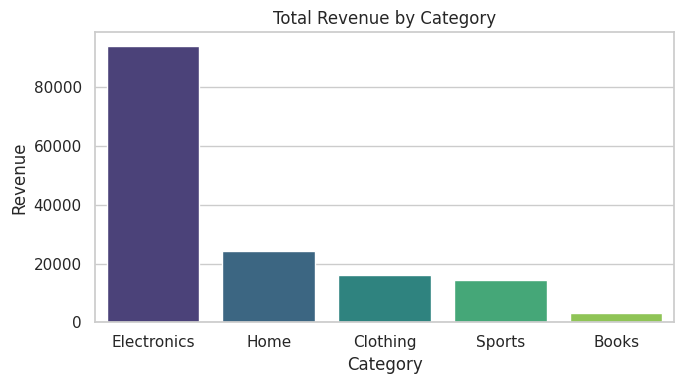

In [11]:
# Bar chart: total revenue by category
cat_rev = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
plt.figure(figsize=(7, 4))
sns.barplot(x=cat_rev.index, y=cat_rev.values, palette="viridis", hue=cat_rev.index, legend=False)
plt.title("Total Revenue by Category"); plt.xlabel("Category"); plt.ylabel("Revenue")
plt.tight_layout(); plt.savefig("figures/01_bar_revenue_by_category.png", dpi=120); plt.show()

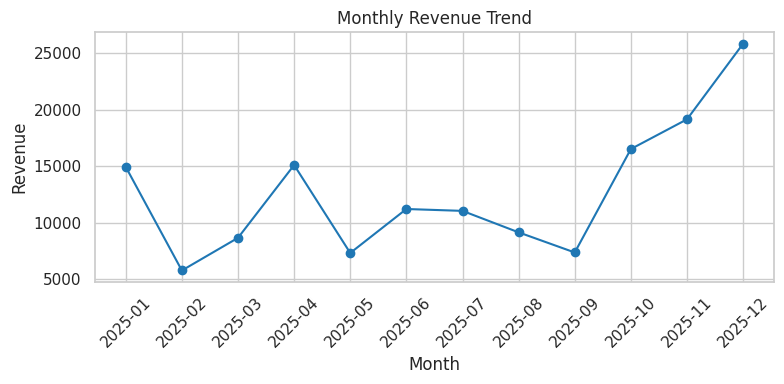

In [12]:
# Line chart: monthly revenue trend
monthly = df.groupby("month")["revenue"].sum()
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, marker="o", color="tab:blue")
plt.xticks(rotation=45); plt.title("Monthly Revenue Trend"); plt.xlabel("Month"); plt.ylabel("Revenue")
plt.tight_layout(); plt.savefig("figures/02_line_monthly_revenue.png", dpi=120); plt.show()

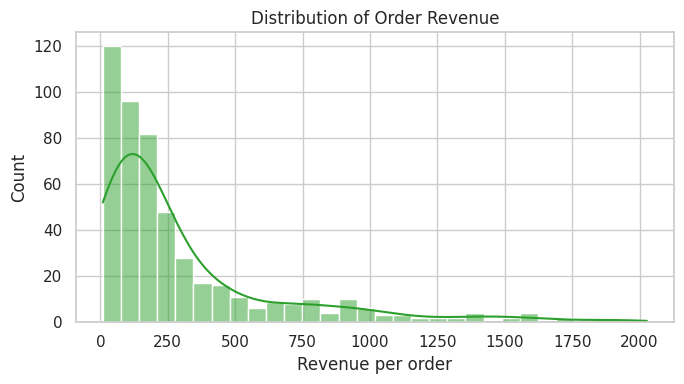

In [13]:
# Histogram: distribution of order revenue
plt.figure(figsize=(7, 4))
sns.histplot(df["revenue"], bins=30, kde=True, color="tab:green")
plt.title("Distribution of Order Revenue"); plt.xlabel("Revenue per order")
plt.tight_layout(); plt.savefig("figures/03_hist_revenue.png", dpi=120); plt.show()

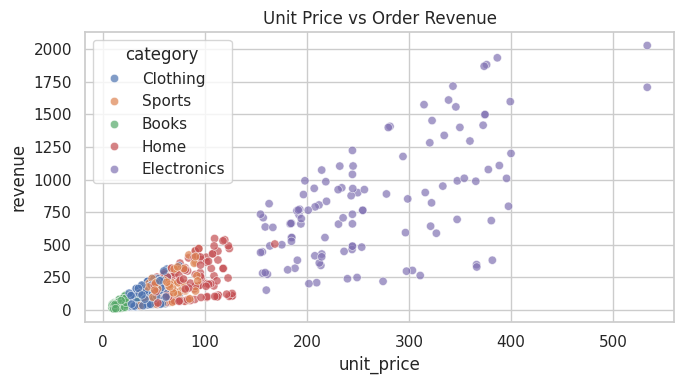

In [14]:
# Scatter plot: unit price vs revenue
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="unit_price", y="revenue", hue="category", alpha=0.7)
plt.title("Unit Price vs Order Revenue")
plt.tight_layout(); plt.savefig("figures/04_scatter_price_revenue.png", dpi=120); plt.show()

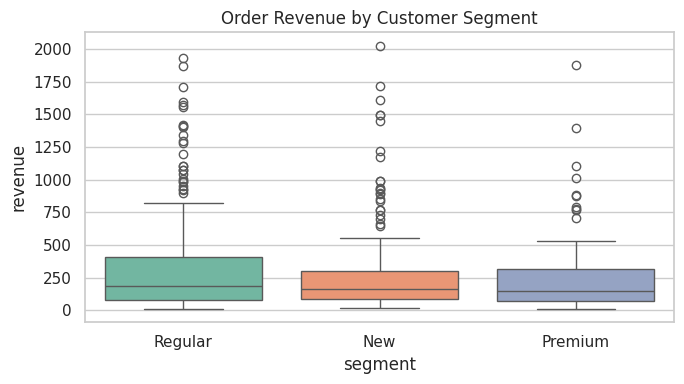

In [15]:
# Box plot: revenue by customer segment
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="segment", y="revenue", hue="segment", palette="Set2", legend=False)
plt.title("Order Revenue by Customer Segment")
plt.tight_layout(); plt.savefig("figures/05_box_revenue_by_segment.png", dpi=120); plt.show()

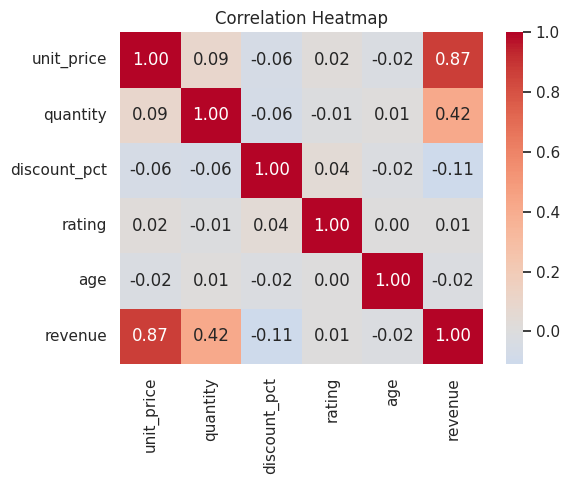

In [16]:
# Correlation heatmap
corr = df[["unit_price", "quantity", "discount_pct", "rating", "age", "revenue"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout(); plt.savefig("figures/06_heatmap_correlation.png", dpi=120); plt.show()

## 7. Basic Data Analysis

In [17]:
print(df[["unit_price", "quantity", "discount_pct", "rating", "revenue"]].describe().round(2).to_string())
print("\nSkewness of revenue:", round(df["revenue"].skew(), 2))
print("Mean vs median revenue:", round(df["revenue"].mean(), 2), "vs", round(df["revenue"].median(), 2))

       unit_price  quantity  discount_pct  rating  revenue
count      500.00    500.00        500.00  500.00   500.00
mean       103.32      3.00          6.20    3.77   304.10
std         99.86      1.39          6.56    1.05   365.09
min          9.07      1.00          0.00    1.00     9.15
25%         41.35      2.00          0.00    3.00    79.90
50%         62.47      3.00          5.00    4.00   167.89
75%        117.95      4.00         10.00    5.00   350.46
max        533.40      5.00         20.00    5.00  2026.91

Skewness of revenue: 2.21
Mean vs median revenue: 304.1 vs 167.89


In [18]:
print(corr["revenue"].drop("revenue").round(2).sort_values(ascending=False).to_string())
print()
print(df.groupby("city")["revenue"].agg(["count", "sum", "mean"]).round(2).sort_values("sum", ascending=False).to_string())
print()
print(df.groupby("segment")["revenue"].mean().round(2).to_string())
print()
print(df.groupby("payment_method")["rating"].mean().round(2).to_string())

unit_price      0.87
quantity        0.42
rating          0.01
age            -0.02
discount_pct   -0.11

           count       sum    mean
city                              
Kochi        110  37593.68  341.76
Kozhikode    105  33138.57  315.61
Bengaluru    112  32354.09  288.88
Chennai      111  29696.96  267.54
Thrissur      62  19266.06  310.74

segment
New        306.25
Premium    259.22
Regular    318.56

payment_method
Card       3.75
Cash       3.79
UPI        3.67
Unknown    3.45
Wallet     3.93


In [19]:
best_cat = cat_rev.index[0]
peak_month = monthly.idxmax()
top_share = cat_rev.iloc[0] / cat_rev.sum() * 100
q4_share = monthly[monthly.index >= "2025-11"].sum() / monthly.sum() * 100

print(f"1. {best_cat} earns the most revenue ({top_share:.1f}% of the total).")
print(f"2. Revenue peaks in {peak_month}; Nov-Dec together make up {q4_share:.1f}% of annual revenue.")
print(f"3. Revenue is right-skewed (skewness {df['revenue'].skew():.2f}); mean {df['revenue'].mean():.1f} is above median {df['revenue'].median():.1f}.")
print(f"4. Unit price has the strongest link with revenue (r = {corr.loc['unit_price', 'revenue']:.2f}); discount is only r = {corr.loc['discount_pct', 'revenue']:.2f}.")
print(f"5. Ratings average {df['rating'].mean():.2f} out of 5.")

1. Electronics earns the most revenue (61.9% of the total).
2. Revenue peaks in 2025-12; Nov-Dec together make up 29.6% of annual revenue.
3. Revenue is right-skewed (skewness 2.21); mean 304.1 is above median 167.9.
4. Unit price has the strongest link with revenue (r = 0.87); discount is only r = -0.11.
5. Ratings average 3.77 out of 5.


## 8. Observations and Insights
- **Cleaning mattered:** 20 duplicate rows, text-based prices, inconsistent category spellings, missing values and extreme prices all had to be fixed before the numbers could be trusted.
- **Revenue is category-driven:** Electronics has the highest unit prices, so it dominates total revenue even though Clothing has the most orders.
- **Seasonality:** revenue climbs from October and peaks in December, when orders are most frequent.
- **Skewed distribution:** a few large orders pull the mean above the median, so the median describes a typical order better.
- **Customers:** Kochi brings in the most revenue, Thrissur has the fewest orders, and differences between customer segments are small, so they should not be over-interpreted.
- **Relationships:** unit price drives revenue far more than discount or customer age. Correlation here describes association only, not cause.
- **Limitations:** the data is synthetic and relatively small, so the patterns demonstrate the methods and should not be read as real market behaviour.

## 9. Conclusion
The lab set up a working data science environment and applied the full workflow: load, inspect, clean, transform, visualise and summarise. The notebook is fully reproducible because the random seed is fixed and the dataset is generated in the first cells.